# The Impact of AI on Jobs by 2030: An Automation-Risk Analysis

## 1. Project Overview

**Purpose.** Artificial intelligence is changing what work looks like. This project uses a dataset of **3,000 worker records across 20 job titles** (source: [Kaggle – AI Impact on Jobs 2030](https://www.kaggle.com/datasets/khushikyad001/ai-impact-on-jobs-2030)) to find out **which jobs are most likely to be automated by 2030, and which commonly assumed "protective" factors (pay, education, experience, AI exposure) actually make a difference.**

**Approach.**
1. Understand the business context and stakeholders.
2. Load and clean the data, and check its quality.
g3. Frame **five business problems**, and answer each with one chart.
4. For every chart: write an **Observation** (what the chart shows), a **Conclusion** (what it means) and a **Recommendation** (what to do about it).



## 2. Business Understanding

**Business context.** Governments, employers, schools and workers are all making long-term decisions (budgets, hiring, curricula, career moves) without a clear picture of which roles AI is likely to automate. Getting this wrong means either wasted training money or workers being caught unprepared.

**Business objective.** Identify the roles and worker groups most exposed to automation by 2030 and give each stakeholder evidence-based actions to reduce that exposure.


**Stakeholders**

| Stakeholder | What they care about | How they will use this analysis |
|---|---|---|
| Government / labour-ministry policy makers | Unemployment, social protection, national skills strategy | Decide where to direct reskilling funds and transition support |
| Education & training providers (universities, technical colleges, bootcamps) | Relevant curricula, graduate employability | Redesign programmes towards roles and skills that stay in demand |
| Employers & HR / workforce-planning leaders | Cost, productivity, retention, redeployment | Plan role redesign, redeployment and upskilling before roles are automated |
| Workers & trade unions | Job security, fair transitions | Negotiate retraining and transition support; understand personal exposure |
| Career counsellors, students & job seekers | Choosing a durable career path | Advise on which occupations are safer and which "safe" assumptions are false |
| Investors & industry bodies | Sector outlook, talent supply | Anticipate labour-cost changes and talent shortages by sector |

**Key questions (the five business problems).**
1. Which jobs face the highest automation risk, and how much of the workforce is that?
2. Does a higher education level protect a worker?
3. Does more work experience protect a worker?
4. Does the AI Exposure Index tell us who is actually at risk
5. what skill combination best insulate roles from high automation risk?
6. How do tech growth trends compare to automation exposure?



- The data was sourced from [Kaggle](https://www.kaggle.com/datasets/khushikyad001/ai-impact-on-jobs-2030)
- The data has the following characteristics
   - Job_Title - The job
   - Average_Salary - Average salary the respective job gets
   - years_Experiencing - Number of years person has been on been on the job
   - Education Level - The level of education a person has
   - AI_Exposure_Index - The level of exposure to AI
   - Tech_Growth_Factor - 
   - Automation_Probability_2030 - How likely will the job be automated by 2030
   - Risk_Category - How risky is the job to be replaced by ai 
   - Skills - Random Skills

In [ ]:
import pandas as pd
import seaborn as sns

Matplotlib is building the font cache; this may take a moment.


In [ ]:
# ---------------------------------------------------------------
# Extra libraries + shared chart styling used by every chart below
# ---------------------------------------------------------------
import matplotlib.pyplot as plt          # base plotting library (seaborn is built on top of it)
import numpy as np                       # numeric helpers
from matplotlib.patches import Patch     # lets us build custom legends

sns.set_theme(style='whitegrid')         # clean white background with light grid lines
plt.rcParams['figure.dpi'] = 110         # sharper charts in the notebook

# One fixed colour per risk level, used in ALL charts so readers can decode them at a glance
# (green = safe, amber = watch, red = danger)
RISK_ORDER  = ['Low', 'Medium', 'High']
RISK_COLORS = {'Low': '#2E8B57', 'Medium': '#F0A030', 'High': '#D64545'}

In [ ]:
data = pd.read_csv('AI_Impact_on_Jobs_2030.csv')

In [ ]:
data.head()

,Job_Title,Average_Salary,Years_Experience,Education_Level,AI_Exposure_Index,Tech_Growth_Factor,Automation_Probability_2030,Risk_Category,Skill_1,Skill_2,Skill_3,Skill_4,Skill_5,Skill_6,Skill_7,Skill_8,Skill_9,Skill_10
0,Security Guard,45795,28,Master's,0.18,1.28,0.85,High,0.45,0.10,0.46,0.33,0.14,0.65,0.06,0.72,0.94,0.00
1,Research Scientist,133355,20,PhD,0.62,1.11,0.05,Low,0.02,0.52,0.40,0.05,0.97,0.23,0.09,0.62,0.38,0.98
2,Construction Worker,146216,2,High School,0.86,1.18,0.81,High,0.01,0.94,0.56,0.39,0.02,0.23,0.24,0.68,0.61,0.83
3,Software Engineer,136530,13,PhD,0.39,0.68,0.60,Medium,0.43,0.21,0.57,0.03,0.84,0.45,0.40,0.93,0.73,0.33
4,Financial Analyst,70397,22,High School,0.52,1.46,0.64,Medium,0.75,0.54,0.59,0.97,0.61,0.28,0.30,0.17,0.02,0.42


In [ ]:
## CLEANING
data.isnull().sum()

Job_Title                      0
Average_Salary                 0
Years_Experience               0
Education_Level                0
AI_Exposure_Index              0
Tech_Growth_Factor             0
Automation_Probability_2030    0
Risk_Category                  0
Skill_1                        0
Skill_2                        0
Skill_3                        0
Skill_4                        0
Skill_5                        0
Skill_6                        0
Skill_7                        0
Skill_8                        0
Skill_9                        0
Skill_10                       0
dtype: int64

In [ ]:
data.duplicated().sum()

np.int64(0)

### Data quality notes
Before analysing, we check how the columns relate to each other. Nulls and duplicates are already zero (above); the checks below look for structural issues that affect how we interpret the results.

In [ ]:
# ---------------------------------------------------------------
# CHECK 1: Is Risk_Category just a re-labelling of the probability?
# ---------------------------------------------------------------
def to_category(p):
    # thresholds inferred from the data: Low <= 0.30, Medium 0.31-0.70, High >= 0.71
    if p <= 0.30:
        return 'Low'
    elif p <= 0.70:
        return 'Medium'
    return 'High'

match = (data['Automation_Probability_2030'].map(to_category) == data['Risk_Category']).mean()
print(f'Risk_Category matches the probability thresholds for {match:.0%} of rows\n')

# ---------------------------------------------------------------
# CHECK 2: Does salary differ between jobs? (min / median / max per job)
# ---------------------------------------------------------------
salary_by_job = data.groupby('Job_Title')['Average_Salary'].agg(['min', 'median', 'max'])
print(salary_by_job.round(0).astype(int).to_string())

# ---------------------------------------------------------------
# CHECK 3: Value ranges of the numeric drivers
# ---------------------------------------------------------------
print('\nYears_Experience range :', data['Years_Experience'].min(), 'to', data['Years_Experience'].max())
print('AI_Exposure_Index range:', data['AI_Exposure_Index'].min(), 'to', data['AI_Exposure_Index'].max())
print('Records per job (min/max):', data['Job_Title'].value_counts().min(), '/', data['Job_Title'].value_counts().max())

Risk_Category matches the probability thresholds for 100% of rows

                       min  median     max
Job_Title                                 
AI Engineer          30030   90705  149245
Chef                 30125   94043  148962
Construction Worker  33063   89613  149107
Customer Support     31112   86153  149798
Data Scientist       30645   91063  149359
Doctor               30893   88326  149756
Financial Analyst    30591   91146  149391
Graphic Designer     31645  103183  149700
HR Specialist        30030   93115  148169
Lawyer               32393   95140  149528
Marketing Manager    30060   85592  149635
Mechanic             30318   91076  149593
Nurse                30511   91926  149401
Research Scientist   30340   84544  148533
Retail Worker        30234   84150  148360
Security Guard       30654   88584  149554
Software Engineer    32599   87803  149318
Teacher              30443   88668  148915
Truck Driver         31996   81290  148623
UX Researcher        31113   8

**What the checks tell us**
- **`Risk_Category` is not independent information.** It matches the automation probability thresholds in 100% of rows (Low <= 0.30, Medium 0.31-0.70, High >= 0.71), so it is a label of `Automation_Probability_2030`, not a separate signal.
- **Salary does not distinguish jobs.** Every job, from Doctor to Retail Worker, spans roughly \$30k to \$150k with a similar median. In real data salary differs strongly by occupation. Combined with records such as a Security Guard with a Master's degree, this strongly suggests the dataset is **synthetic**, so the conclusions describe *this dataset* and should be validated on real data.
- **Undocumented columns.** `Tech_Growth_Factor` has no description at source, and `Skill_1`-`Skill_10` are anonymous 0-1 scores, so we do not use them to draw business conclusions.
- Job titles are well balanced (roughly 130-175 records each), so no job is over- or under-represented.

 ### ASSIGNMENT 


---
## 3. Business Problems, Charts, Observations, Conclusions & Recommendations

### Business Problem 1: Which jobs face the highest automation risk by 2030, and how much of the workforce do they represent?
*Why it matters:* Policy makers and employers can only prioritise support if they know exactly which roles are most exposed and how many people are in them.

High-risk jobs: ['Truck Driver', 'Customer Support', 'Construction Worker', 'Security Guard', 'Retail Worker']
They account for 751 of 3,000 records (25% of the workforce sample)
Share of workers in those jobs classed High risk: 99%


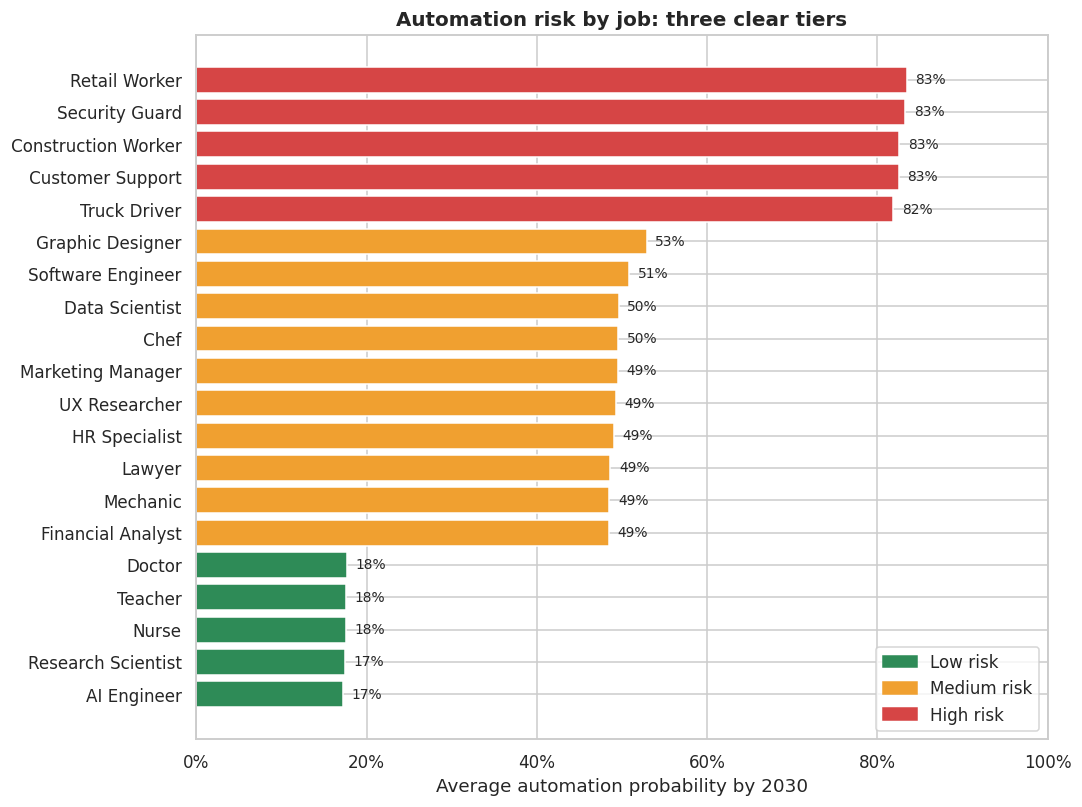

In [ ]:
# ---------------------------------------------------------------
# PROBLEM 1 CHART: average automation probability per job (ranked)
# ---------------------------------------------------------------
# Average the 2030 automation probability for each job title and sort from lowest to highest
job_risk = data.groupby('Job_Title')['Automation_Probability_2030'].mean().sort_values()

# Colour each bar by the risk tier its average falls into (reuses to_category from the data-quality cell)
bar_colors = [RISK_COLORS[to_category(p)] for p in job_risk]

fig, ax = plt.subplots(figsize=(10, 7.5))
ax.barh(job_risk.index, job_risk.values, color=bar_colors)

# Write the % value at the end of each bar so no one has to read it off the axis
for i, v in enumerate(job_risk.values):
    ax.text(v + 0.01, i, f'{v:.0%}', va='center', fontsize=9)

ax.set_xlim(0, 1)
ax.xaxis.set_major_formatter(lambda v, _: f'{v:.0%}')
ax.set_xlabel('Average automation probability by 2030')
ax.set_title('Automation risk by job: three clear tiers', fontsize=13, fontweight='bold')
ax.legend(handles=[Patch(color=RISK_COLORS[c], label=f'{c} risk') for c in RISK_ORDER],
          loc='lower right')
plt.tight_layout()
plt.show()

# Supporting numbers for the written observation
high_jobs = job_risk[job_risk > 0.70].index.tolist()
in_high   = data['Job_Title'].isin(high_jobs)
print('High-risk jobs:', high_jobs)
print(f'They account for {in_high.sum():,} of {len(data):,} records ({in_high.mean():.0%} of the workforce sample)')
print(f'Share of workers in those jobs classed High risk: {(data[in_high]["Risk_Category"] == "High").mean():.0%}')

**Observation**
- The 20 jobs fall into **three distinct tiers**, with almost no overlap between them.
- **High risk (about 82-83%):** Truck Driver, Security Guard, Retail Worker, Customer Support and Construction Worker.
- **Medium risk (about 49-53%):** ten jobs including Lawyer, Financial Analyst, Software Engineer, Data Scientist and Graphic Designer.
- **Low risk (about 17-18%):** AI Engineer, Research Scientist, Nurse, Doctor and Teacher.
- The five high-risk jobs make up **25% of the records** (751 of 3,000), and 98-100% of the workers in each are classed as High risk.

**Conclusion**
Automation risk is driven by **the nature of the job, not the individual worker**. Roles built on routine, repetitive or scripted tasks (driving, guarding, retail, first-line support, construction) are the most exposed, while roles built on human care, teaching and advanced research or AI development are the least. Roughly one in four workers sits in a job that is very likely to be automated by 2030.

**Recommendations**
1. **Policy makers:** direct reskilling budgets and transition support first to the five high-risk occupations, rather than spreading funds evenly.
2. **Employers in high-risk roles:** start redeployment and upskilling plans now (for example, moving customer-support staff towards complex-case handling and AI-tool oversight) instead of waiting for roles to disappear.
3. **Education providers & career counsellors:** promote pathways into the low-risk fields (health, education, research/AI) and warn students about the exposure of routine-task careers.
4. **Everyone:** track the ten medium-risk jobs annually, since they sit in the middle and could move up or down as technology changes.

---
### Business Problem 2: Does higher pay protect a job from automation?
*Why it matters:* Many people assume well-paid work is safe. If that is false, support programmes based on income bracket would miss many at-risk workers.

                mean  median    min     max
Risk_Category                              
Low            89167   87889  30030  149756
Medium         90451   91775  30030  149700
High           87359   86120  30234  149798

Mean salary gap, Low-risk vs High-risk: $1,807


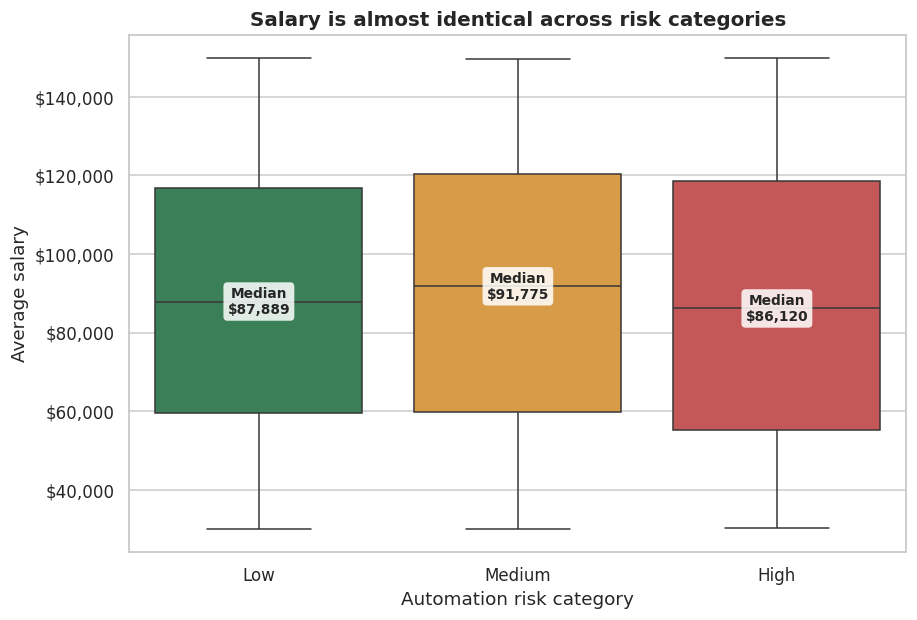

In [ ]:
# ---------------------------------------------------------------
# PROBLEM 2 CHART: salary distribution for each risk category
# ---------------------------------------------------------------
fig, ax = plt.subplots(figsize=(8.5, 5.8))

# Box plot: the box is the middle 50% of salaries, the line inside is the median
sns.boxplot(data=data, x='Risk_Category', y='Average_Salary', order=RISK_ORDER,
            hue='Risk_Category', palette=RISK_COLORS, legend=False, ax=ax)

# Label each median so the comparison is explicit
medians = data.groupby('Risk_Category')['Average_Salary'].median()
for i, cat in enumerate(RISK_ORDER):
    ax.text(i, medians[cat], f'Median\n${medians[cat]:,.0f}', ha='center', va='center',
            fontsize=9, fontweight='bold', bbox=dict(boxstyle='round', fc='white', alpha=0.85, ec='none'))

ax.yaxis.set_major_formatter(lambda v, _: f'${v:,.0f}')
ax.set_xlabel('Automation risk category')
ax.set_ylabel('Average salary')
ax.set_title('Salary is almost identical across risk categories', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

# Supporting numbers
print(data.groupby('Risk_Category')['Average_Salary'].agg(['mean', 'median', 'min', 'max']).loc[RISK_ORDER].round(0).astype(int))
gap = data.loc[data['Risk_Category'] == 'Low', 'Average_Salary'].mean() - data.loc[data['Risk_Category'] == 'High', 'Average_Salary'].mean()
print(f'\nMean salary gap, Low-risk vs High-risk: ${gap:,.0f}')

**Observation**
- The three boxes **overlap almost completely**. Median salary is \$87,889 for Low risk, \$91,775 for Medium and \$86,120 for High.
- The gap between Low and High risk is only **about \$1,800 (roughly 2%)**.
- Every category spans nearly the full range of about \$30k to \$150k, so there are very well-paid workers in high-risk jobs and low-paid workers in low-risk jobs.

**Conclusion**
**Pay is not a shield against automation.** A high salary tells us almost nothing about whether a job will be automated, so income is a poor proxy for job security.

**Recommendations**
1. **Policy makers:** target transition support by **occupation**, not by income bracket. Income-based eligibility would miss well-paid workers in exposed roles.
2. **Employers:** include highly paid roles in automation-risk reviews, since they are not automatically safe and are often the costliest to replace.
3. **Workers & counsellors:** do not treat a good salary as evidence of long-term security. Keep skills current regardless of pay.

---
### Business Problem 3: Does a higher education level protect a worker from automation?
*Why it matters:* Education providers and families invest heavily in degrees on the belief that more education means safer employment.

Education_Level
High School    0.509
Bachelor's     0.500
Master's       0.496
PhD            0.500
Name: Automation_Probability_2030, dtype: float64


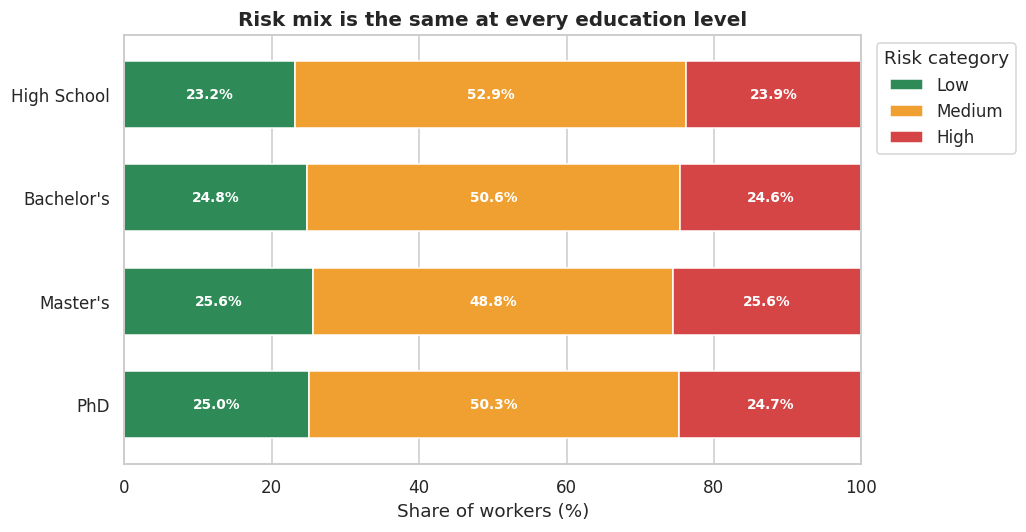

In [ ]:
# ---------------------------------------------------------------
# PROBLEM 3 CHART: risk mix (%) within each education level
# ---------------------------------------------------------------
EDU_ORDER = ['High School', "Bachelor's", "Master's", 'PhD']   # lowest to highest qualification

# crosstab(normalize='index') converts counts into row percentages, so every bar adds up to 100%
edu_share = (pd.crosstab(data['Education_Level'], data['Risk_Category'], normalize='index')
               .loc[EDU_ORDER, RISK_ORDER] * 100)

fig, ax = plt.subplots(figsize=(9.5, 5))
edu_share.plot(kind='barh', stacked=True, ax=ax, width=0.65,
               color=[RISK_COLORS[c] for c in RISK_ORDER])

# Print the % inside each coloured segment
for container in ax.containers:
    ax.bar_label(container, fmt='%.1f%%', label_type='center', color='white', fontweight='bold', fontsize=9)

ax.invert_yaxis()                      # High School at the top, PhD at the bottom
ax.set_xlim(0, 100)
ax.set_xlabel('Share of workers (%)')
ax.set_ylabel('')
ax.set_title('Risk mix is the same at every education level', fontsize=13, fontweight='bold')
ax.legend(title='Risk category', bbox_to_anchor=(1.01, 1), loc='upper left')
plt.tight_layout()
plt.show()

# Supporting numbers: average automation probability per education level
print(data.groupby('Education_Level')['Automation_Probability_2030'].mean().loc[EDU_ORDER].round(3))

**Observation**
- The proportions of Low, Medium and High risk workers are **nearly identical** at all four education levels.
- The High-risk share ranges only from **23.9% (High School) to 25.6% (Master's)**, and the Low-risk share from 23.2% to 25.6%.
- Average automation probability is about **0.50 at every level** (0.496 to 0.509). A PhD holder is no safer than someone with a high-school certificate.

**Conclusion**
**Education level, on its own, does not reduce automation risk.** What a person is trained *for*, meaning their occupation, matters far more than how many years they studied.

**Recommendations**
1. **Education providers:** shift the emphasis from the *level* of qualification to the *content*. Build human-centred, AI-complementary skills (judgement, care, communication, AI-tool fluency) into programmes at every level.
2. **Policy makers:** fund short-cycle reskilling for graduates as well as non-graduates, and do not assume degree holders need less transition support.
3. **Career counsellors & students:** advise on the occupation a qualification leads to. Choosing a degree that feeds a low-risk field matters more than choosing a higher degree.

---
### Business Problem 4: Does more work experience protect a worker from automation?
*Why it matters:* Employers often assume veterans are safer and early-career staff are more replaceable (or the reverse). Reskilling programmes need to know which career stage to focus on.

Correlation (experience vs automation probability): -0.018
Experience_Band
0-4      0.512
5-9      0.517
10-14    0.487
15-19    0.497
20-24    0.479
25-29    0.516
Name: Automation_Probability_2030, dtype: float64


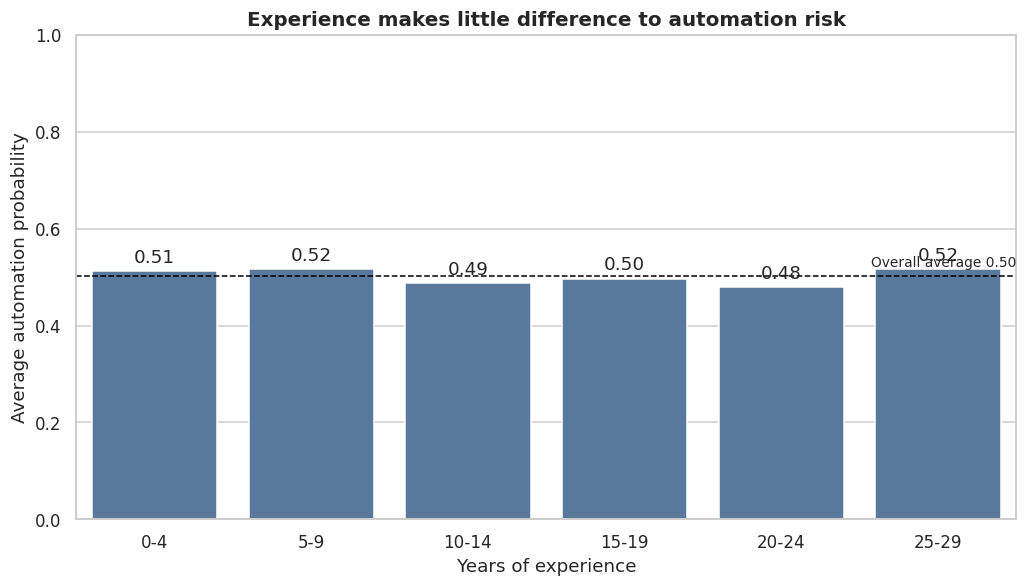

In [ ]:
# ---------------------------------------------------------------
# PROBLEM 4 CHART: average automation probability by years of experience
# ---------------------------------------------------------------
# Group experience (0-29 years) into 5-year bands so the chart is readable.
# NOTE: this adds a helper column 'Experience_Band' to the dataframe.
bins   = [-1, 4, 9, 14, 19, 24, 29]
labels = ['0-4', '5-9', '10-14', '15-19', '20-24', '25-29']
data['Experience_Band'] = pd.cut(data['Years_Experience'], bins=bins, labels=labels)

exp_risk = data.groupby('Experience_Band', observed=True)['Automation_Probability_2030'].mean()
overall  = data['Automation_Probability_2030'].mean()

fig, ax = plt.subplots(figsize=(9.5, 5.5))
sns.barplot(x=exp_risk.index, y=exp_risk.values, color='#4C78A8', ax=ax)
ax.bar_label(ax.containers[0], fmt='%.2f', padding=3)

# Dashed line = overall average, to show how little each band deviates from it
ax.axhline(overall, color='black', linestyle='--', linewidth=1)
ax.text(len(exp_risk) - 0.5, overall + 0.02, f'Overall average {overall:.2f}', ha='right', fontsize=9)

# Y-axis starts at 0 and runs to 1 (the true probability scale) so small differences are not exaggerated
ax.set_ylim(0, 1)
ax.set_xlabel('Years of experience')
ax.set_ylabel('Average automation probability')
ax.set_title('Experience makes little difference to automation risk', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

# Supporting number: correlation between experience and automation probability
print('Correlation (experience vs automation probability):',
      round(data['Years_Experience'].corr(data['Automation_Probability_2030']), 3))
print(exp_risk.round(3))

**Observation**
- Average automation probability sits between **0.48 and 0.52** in every experience band, all close to the overall average of 0.50.
- There is **no upward or downward trend**. Workers with 25-29 years (0.52) look the same as new entrants with 0-4 years (0.51).
- The correlation between experience and automation probability is about **-0.02**, effectively zero.

**Conclusion**
**Experience does not protect a worker from automation, and being early in a career does not increase risk either.** Risk is spread evenly across career stages.

**Recommendations**
1. **Employers:** offer reskilling to workers at **all** career stages, including mid- and late-career staff who are sometimes overlooked, and set up knowledge-transfer between veterans and new hires.
2. **HR leaders:** do not use tenure as a proxy for resilience when planning workforce changes. Assess the *role*, not the person's years of service.
3. **Policy makers & unions:** design transition programmes that work for older workers (flexible, paid-time learning) as well as school leavers.

---
### Business Problem 5: Does the AI Exposure Index tell us who is actually at risk of automation?
*Why it matters:* Organisations often screen roles using an "AI exposure" score. If that score does not track automation risk, screening decisions built on it could be wrong.

Risk_Category   Low  Medium  High
Exposure_Band                    
Low exposure   24.8    51.3  23.9
Mid exposure   24.4    50.8  24.8
High exposure  24.7    50.0  25.3


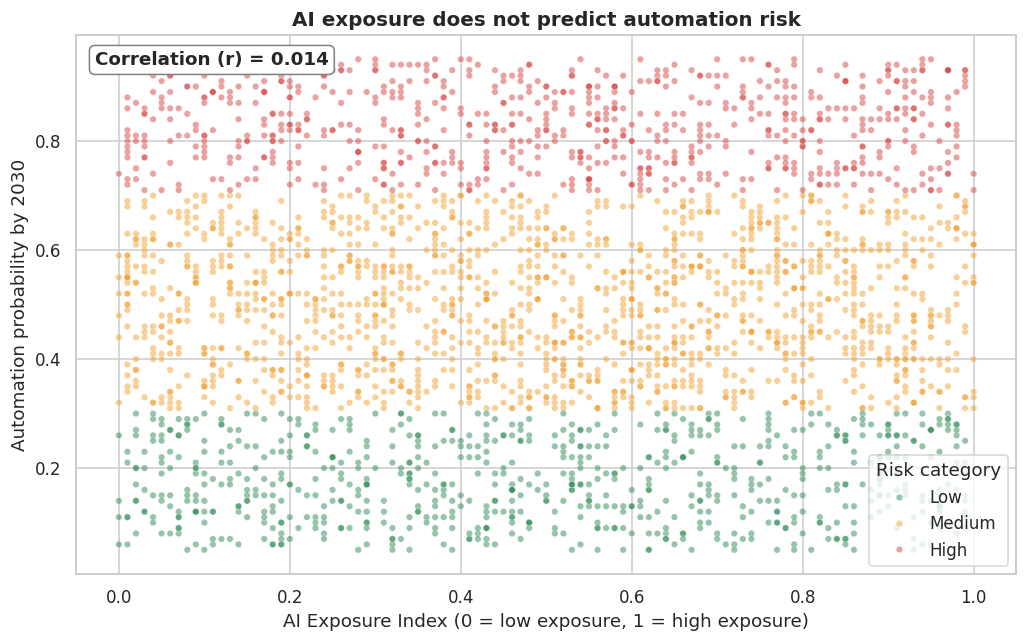

In [ ]:
# ---------------------------------------------------------------
# PROBLEM 5 CHART: AI exposure vs automation probability (one dot = one worker)
# ---------------------------------------------------------------
fig, ax = plt.subplots(figsize=(9.5, 6))
sns.scatterplot(data=data, x='AI_Exposure_Index', y='Automation_Probability_2030',
                hue='Risk_Category', hue_order=RISK_ORDER, palette=RISK_COLORS,
                alpha=0.5, s=18, ax=ax)

# Correlation coefficient (r): +1 = perfect upward link, 0 = no link, -1 = perfect downward link
r = data['AI_Exposure_Index'].corr(data['Automation_Probability_2030'])
ax.text(0.02, 0.97, f'Correlation (r) = {r:.3f}', transform=ax.transAxes, va='top',
        fontweight='bold', bbox=dict(boxstyle='round', fc='white', ec='grey'))

ax.set_xlabel('AI Exposure Index (0 = low exposure, 1 = high exposure)')
ax.set_ylabel('Automation probability by 2030')
ax.set_title('AI exposure does not predict automation risk', fontsize=13, fontweight='bold')
ax.legend(title='Risk category', loc='lower right')
plt.tight_layout()
plt.show()

# Supporting numbers: share of each risk category within Low / Mid / High exposure bands
data['Exposure_Band'] = pd.cut(data['AI_Exposure_Index'], bins=[0, 0.33, 0.66, 1.0],
                               labels=['Low exposure', 'Mid exposure', 'High exposure'], include_lowest=True)
print((pd.crosstab(data['Exposure_Band'], data['Risk_Category'], normalize='index')[RISK_ORDER] * 100).round(1))

**Observation**
- The dots form **three flat horizontal bands** (Low, Medium, High risk) that run across the *entire* 0-1 exposure range. Knowing a worker's exposure score does not tell you which band they are in.
- The correlation is **0.014**, essentially zero.
- The High-risk share is 23.9% among low-exposure workers, 24.8% among mid-exposure and 25.3% among high-exposure workers, so it barely moves.

**Conclusion**
**The AI Exposure Index is not a useful predictor of automation risk in this data.** Being *exposed* to AI (for example, AI tools changing how work is done) is not the same as being *replaceable* by it. Either the index measures something different from automation, or it is unreliable.

**Recommendations**
1. **Employers & analysts:** do not screen roles using the exposure index alone. Use job-level automation probability or a task-level analysis of which duties can actually be automated.
2. **Data team:** request documentation of how the index is built, and validate it against real labour-market data before it is used for decisions.
3. **Policy makers:** separate the two ideas in planning: roles that AI will *augment* (support with tools and training) versus roles it will *replace* (support with transition and redeployment).

---
## 4. Summary of Findings & Recommendations

| # | Business problem | Key conclusion | Main recommendation |
|---|---|---|---|
| 1 | Which jobs are most at risk? | Risk depends on the job: 5 jobs (25% of workers) are ~83% likely to be automated, 5 are only ~17-18% | Prioritise reskilling and transition funds for the five high-risk occupations |
| 2 | Does higher pay protect? | No: median pay is nearly the same across risk categories (gap ~\$1,800) | Target support by occupation, not income bracket |
| 3 | Does education protect? | No: risk mix is the same at every education level | Focus on the *content* of training, not just the level |
| 4 | Does experience protect? | No: automation probability is ~0.50 at every career stage | Offer reskilling to workers at all career stages |
| 5 | Does AI exposure predict risk? | No: correlation is 0.014 | Use job-level or task-level risk rather than the exposure index alone |

**Overall message.** Occupation is the single factor that matters. Pay, degrees, years of service and AI exposure scores give a false sense of security.

**Limitations & next steps**
- The dataset looks synthetic (identical salary ranges in every job, implausible job/education combinations), so validate these findings on real labour-market data before acting on them.
- Automation probability is an estimate. It says nothing about *when* jobs change or whether workers are redeployed rather than dismissed.
- Next steps: obtain documentation for `Tech_Growth_Factor` and the ten skill scores, test whether specific skills reduce risk within a job, and repeat the analysis on a real dataset.